# Regression Track: CarDekho Used Car Price Prediction
### 23CSE301 Machine Learning: Capstone Project, Review 1

**Dataset:** `cardekho_dataset.csv` with 15,411 used-car listings.
**Target:** `selling_price` (continuous, INR).

This notebook covers **Section A: Dataset & EDA** and **Section B: Preprocessing & Feature Engineering**.


## Imports

In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Section A: Dataset & EDA

## A1. Dataset Loading & Audit

In [37]:
df = pd.read_csv("cardekho_dataset.csv")

print("Original dataset shape:", df.shape)
print("\nData types:")
display(df.dtypes)

print("\nMissing values per column:")
display(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nTarget variable summary — selling_price (INR):")
display(df["selling_price"].describe())

print("\nTarget skewness:", round(df["selling_price"].skew(), 2))

Original dataset shape: (15411, 14)

Data types:


Unnamed: 0             int64
car_name              object
brand                 object
model                 object
vehicle_age            int64
km_driven              int64
seller_type           object
fuel_type             object
transmission_type     object
mileage              float64
engine                 int64
max_power            float64
seats                  int64
selling_price          int64
dtype: object


Missing values per column:


Unnamed: 0           0
car_name             0
brand                0
model                0
vehicle_age          0
km_driven            0
seller_type          0
fuel_type            0
transmission_type    0
mileage              0
engine               0
max_power            0
seats                0
selling_price        0
dtype: int64


Total missing values: 0

Duplicate rows: 0

Target variable summary — selling_price (INR):


count    1.541100e+04
mean     7.749711e+05
std      8.941284e+05
min      4.000000e+04
25%      3.850000e+05
50%      5.560000e+05
75%      8.250000e+05
max      3.950000e+07
Name: selling_price, dtype: float64


Target skewness: 10.05


### A1 Observation

The dataset contains **15,411 observations and 14 columns** before removing the CSV index column. `selling_price` is a continuous numerical target, so this is a supervised regression problem.

The initial audit found **no missing values and no exact duplicate rows**. The target is positively skewed, with a mean higher than the median, indicating a long upper tail of higher-priced vehicles.


## A2. EDA Visualisations

### A2.1 Distribution Plots for Numerical Features

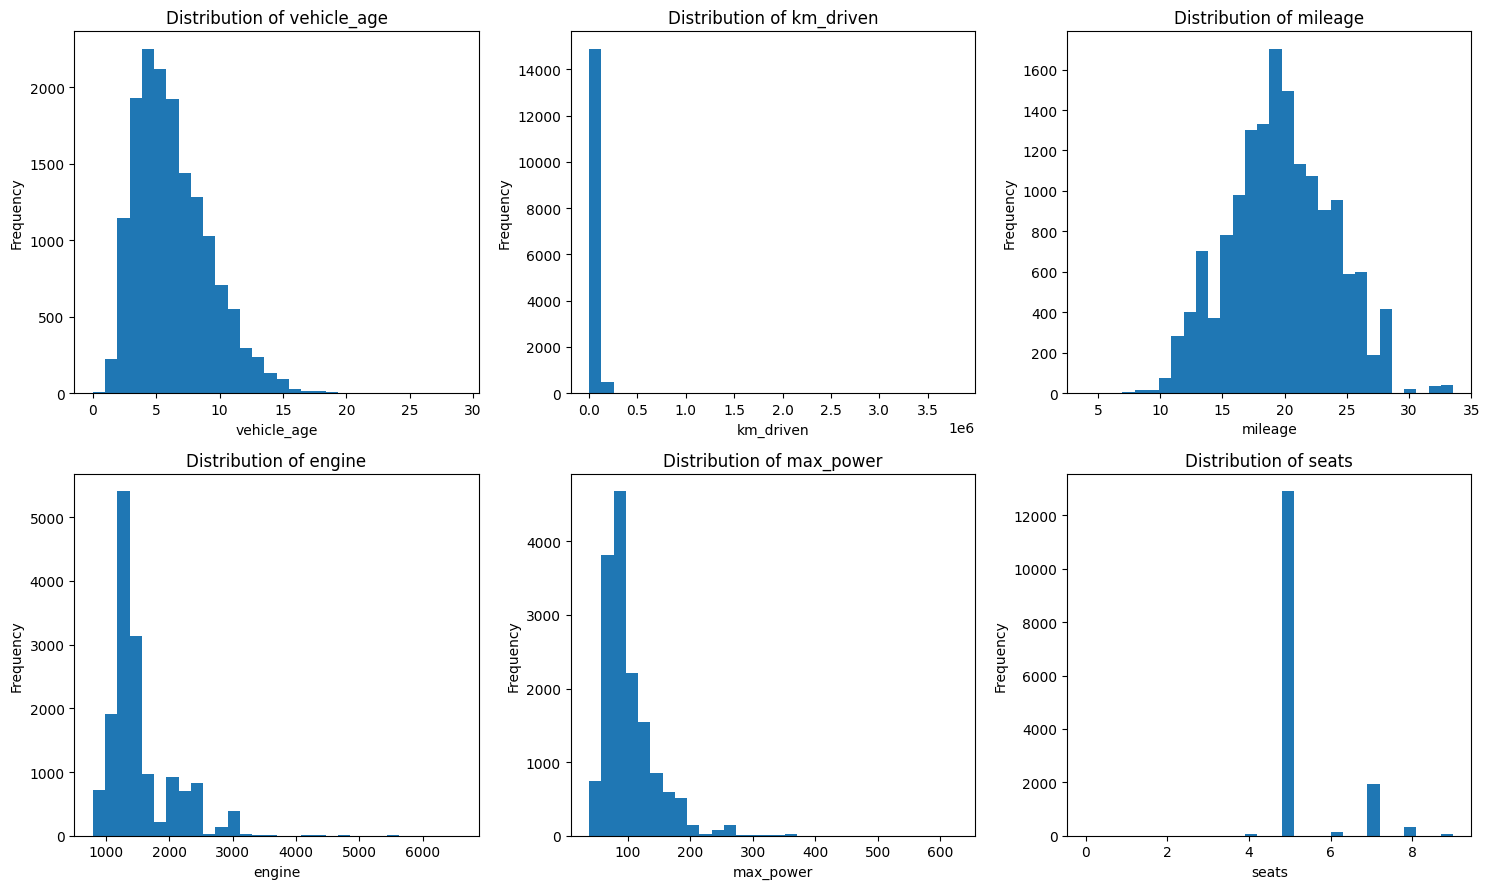

In [38]:
numeric_features = [
    "vehicle_age",
    "km_driven",
    "mileage",
    "engine",
    "max_power",
    "seats"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for ax, col in zip(axes, numeric_features):
    ax.hist(df[col], bins=30)
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

### Observation: Numerical Distributions

The numerical features have noticeably different distributions and scales. `km_driven` is strongly right-skewed because a relatively small number of vehicles have very high recorded usage. `engine` and `max_power` also have upper-tail observations, while `vehicle_age` is concentrated over a comparatively limited range.

These differences are relevant for preprocessing: scale-sensitive algorithms such as Ridge, Lasso, ElasticNet, SVR and KNN will require consistent numerical scaling, whereas tree-based models are not dependent on feature scale.

### A2.2 Distribution Plots for Categorical Features

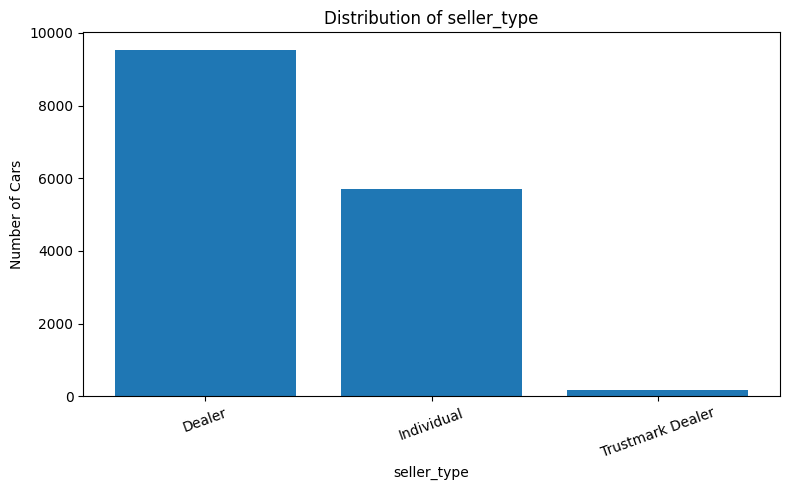

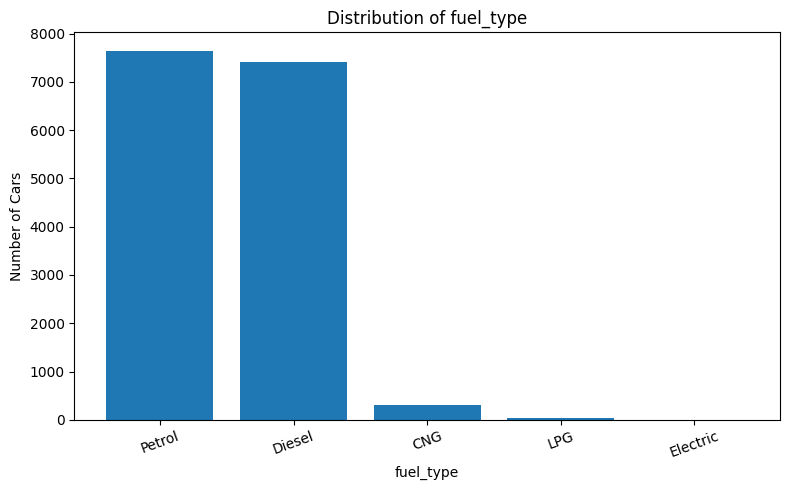

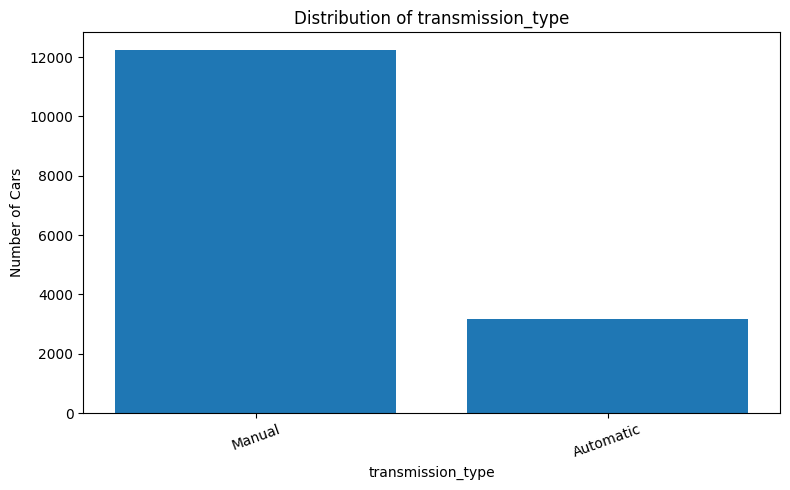

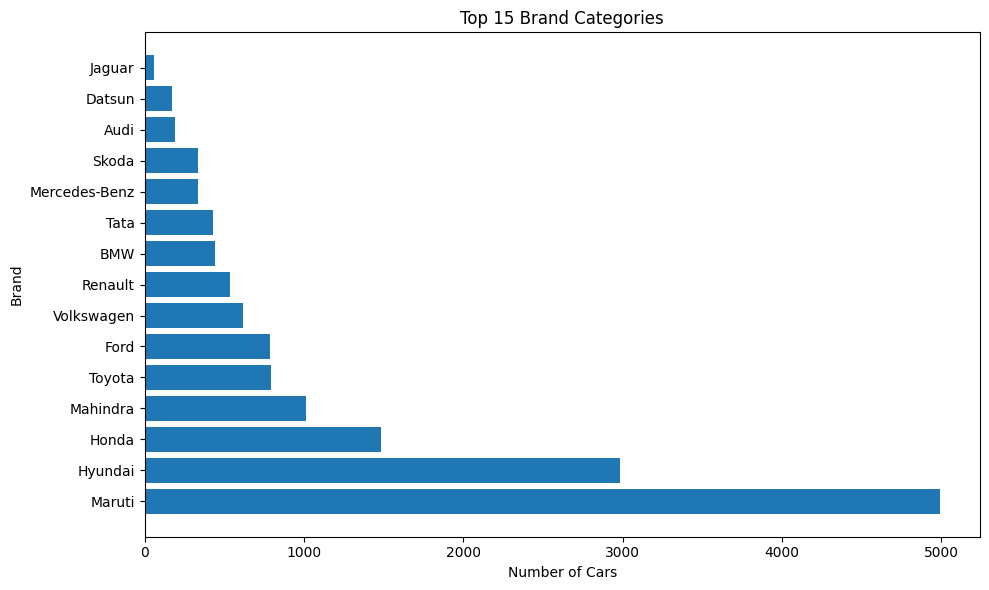

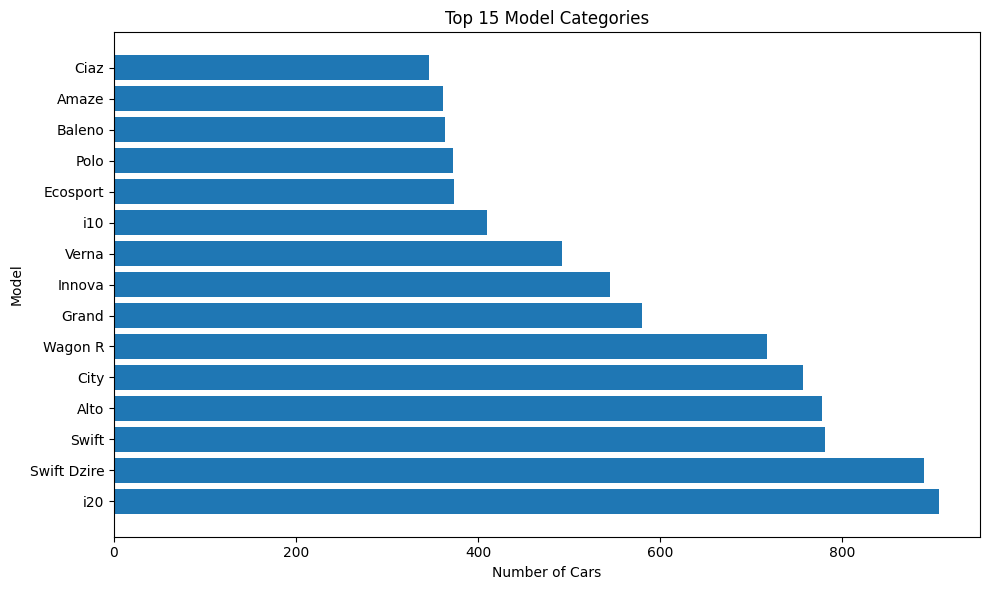

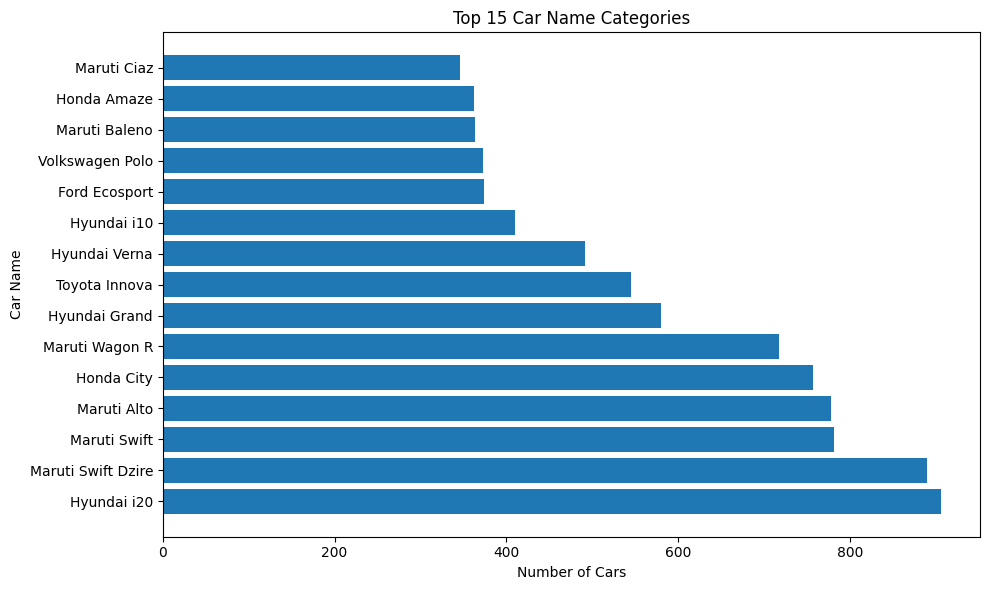

In [39]:
categorical_features = ["seller_type", "fuel_type", "transmission_type"]

for col in categorical_features:
    counts = df[col].value_counts()
    plt.figure(figsize=(8, 5))
    plt.bar(counts.index.astype(str), counts.values)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Number of Cars")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

for col in ["brand", "model", "car_name"]:
    top = df[col].value_counts().head(15)
    plt.figure(figsize=(10, 6))
    plt.barh(top.index.astype(str), top.values)
    plt.title(f"Top 15 {col.replace('_', ' ').title()} Categories")
    plt.xlabel("Number of Cars")
    plt.ylabel(col.replace('_', ' ').title())
    plt.tight_layout()
    plt.show()


### Observation: Categorical Distributions

The categorical variables are unevenly distributed. A smaller number of brands, models and car names account for a larger share of the listings, while less common categories occur less frequently. `seller_type`, `fuel_type` and `transmission_type` have relatively few categories.

These variables are treated as categorical features so that the model does not assume an artificial numerical order between categories.


### A2.3 Correlation Heatmap

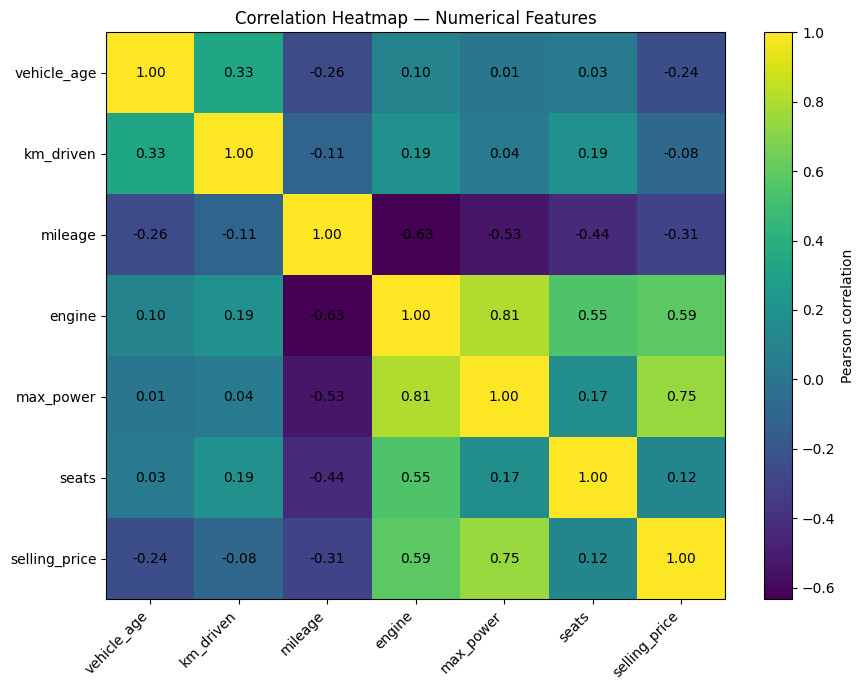

In [40]:
corr_cols = numeric_features + ["selling_price"]
corr_matrix = df[corr_cols].corr()

plt.figure(figsize=(9, 7))
plt.imshow(corr_matrix, aspect="auto")
plt.colorbar(label="Pearson correlation")
plt.xticks(range(len(corr_matrix.columns)), corr_matrix.columns, rotation=45, ha="right")
plt.yticks(range(len(corr_matrix.columns)), corr_matrix.columns)

for i in range(len(corr_matrix.columns)):
    for j in range(len(corr_matrix.columns)):
        plt.text(j, i, f"{corr_matrix.iloc[i, j]:.2f}", ha="center", va="center")

plt.title("Correlation Heatmap — Numerical Features")
plt.tight_layout()
plt.show()

### Observation: Correlation Analysis

Among the numerical predictors, `max_power` has the strongest positive linear association with `selling_price` (approximately **0.75**), followed by `engine` (approximately **0.59**). `mileage` and `vehicle_age` show negative associations with price, while `km_driven` has a relatively weak negative linear correlation.

These relationships suggest that vehicle performance and specifications are important predictors of price. However, correlation measures only linear association and does not capture all nonlinear relationships.

High correlation is **not treated as evidence of data leakage**: these vehicle specifications are characteristics that can legitimately be available when predicting a vehicle's selling price.

### A2.4 Target Distribution

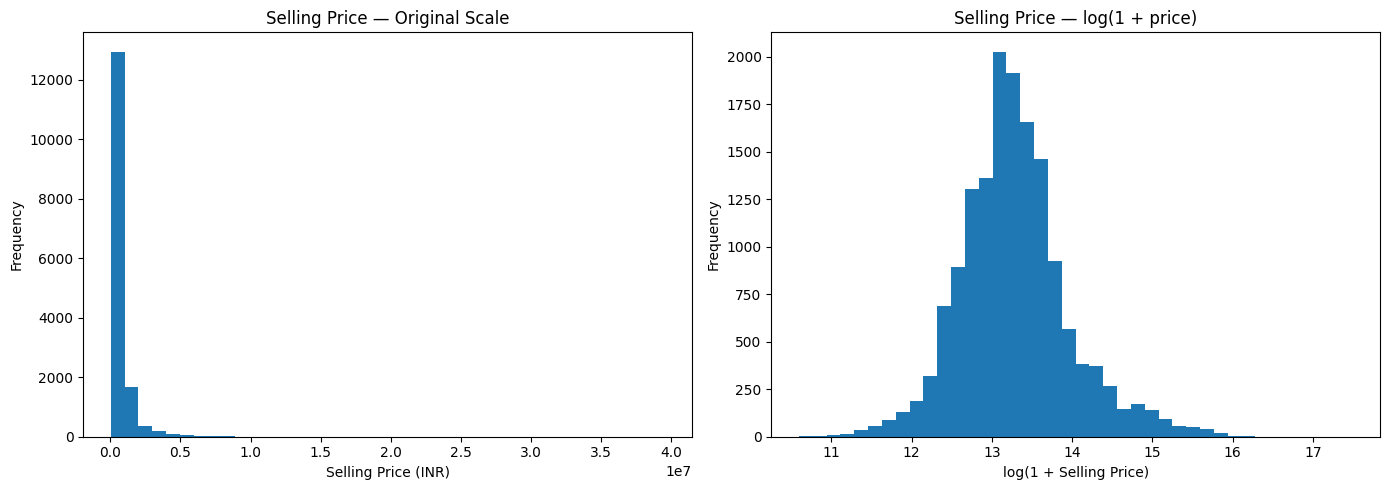

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df["selling_price"], bins=40)
axes[0].set_title("Selling Price — Original Scale")
axes[0].set_xlabel("Selling Price (INR)")
axes[0].set_ylabel("Frequency")

axes[1].hist(np.log1p(df["selling_price"]), bins=40)
axes[1].set_title("Selling Price — log(1 + price)")
axes[1].set_xlabel("log(1 + Selling Price)")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

### Observation: Target Distribution

The raw `selling_price` distribution is strongly right-skewed, with most vehicles concentrated in the lower-to-middle price range and a relatively small number of high-priced vehicles forming a long upper tail.

The `log1p` transformation produces a substantially more compact and symmetric-looking distribution. This makes a log-transformed target a candidate modelling strategy, but its usefulness will be evaluated empirically rather than assumed in advance.

### A2.5 Feature-Target Relationships

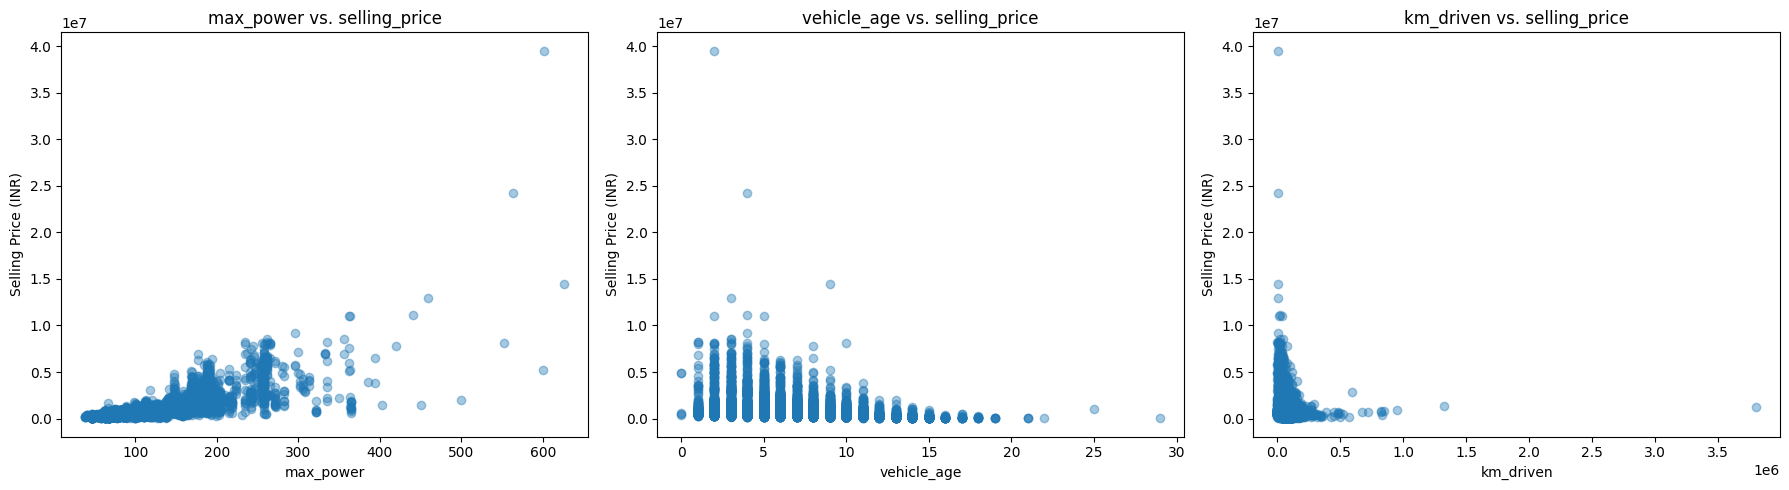

In [42]:
scatter_features = ["max_power", "vehicle_age", "km_driven"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, col in zip(axes, scatter_features):
    ax.scatter(df[col], df["selling_price"], alpha=0.4)
    ax.set_title(f"{col} vs. selling_price")
    ax.set_xlabel(col)
    ax.set_ylabel("Selling Price (INR)")

plt.tight_layout()
plt.show()

### Observations: Feature-Target Relationships

**`max_power` vs. `selling_price`:** The relationship is clearly positive, with higher-powered vehicles generally associated with higher selling prices. The spread also indicates that power alone does not completely determine price.

**`vehicle_age` vs. `selling_price`:** The relationship is generally negative. Newer vehicles tend to have higher prices, while older vehicles are more concentrated at lower prices. The spread suggests that brand, model and vehicle specifications also contribute substantially.

**`km_driven` vs. `selling_price`:** The relationship is comparatively weak and dispersed. Higher usage is generally associated with lower prices, but vehicles with similar kilometre readings can have substantially different prices. This is consistent with the weak linear correlation observed in the heatmap.

### A2.6 Boxplots and Outlier Visualisation

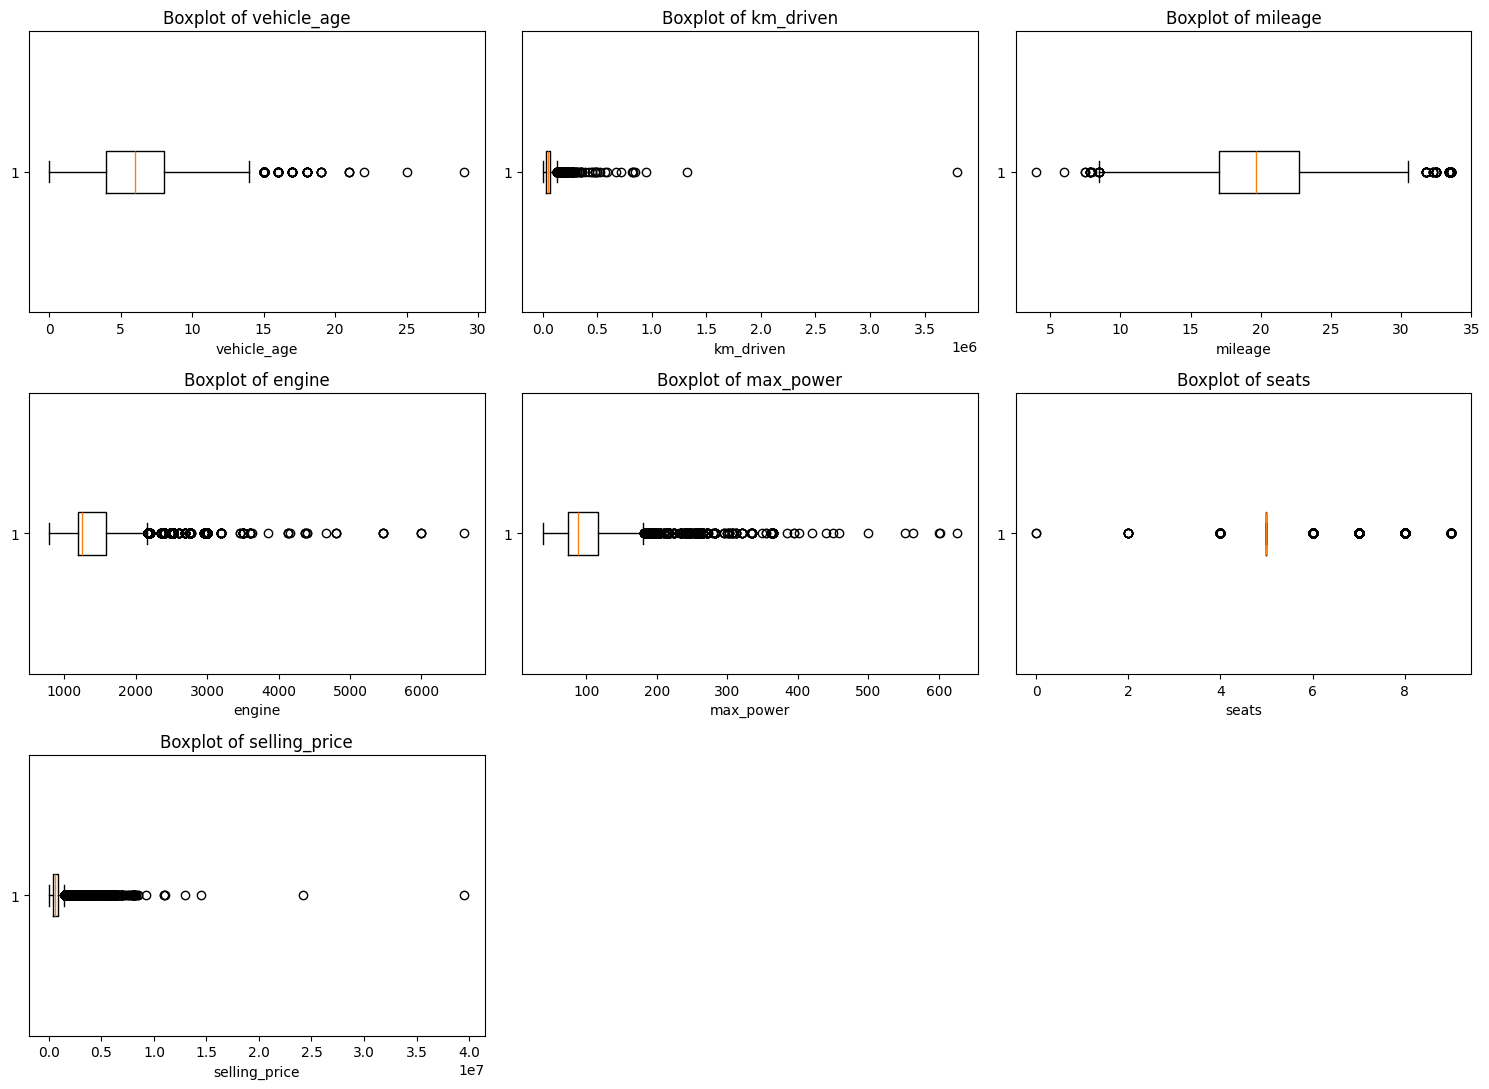

In [43]:
boxplot_features = numeric_features + ["selling_price"]

fig, axes = plt.subplots(3, 3, figsize=(15, 11))
axes = axes.flatten()

for ax, col in zip(axes, boxplot_features):
    ax.boxplot(df[col].dropna(), vert = False)
    ax.set_title(f"Boxplot of {col}")
    ax.set_xlabel(col)

for ax in axes[len(boxplot_features):]:
    fig.delaxes(ax)

plt.tight_layout()
plt.show()

### Observation: Boxplots and Outliers

The boxplots identify statistically unusual observations in several numerical variables. However, an IQR-based outlier is not automatically an erroneous observation. For example, high engine capacity, high maximum power and high selling price can legitimately occur for premium or high-performance vehicles.

Therefore, the boxplots are treated as an **investigation tool**, not as an automatic rule for deleting observations. The extreme records are examined in the preprocessing section before any treatment is applied.

### A2.7 EDA Summary

### Key Insights from EDA

1. `selling_price` is strongly right-skewed, with a smaller group of high-value vehicles.
2. `max_power` and `engine` have the strongest positive linear associations with selling price among the numerical predictors.
3. `vehicle_age` has a negative relationship with price, while `km_driven` has a weak linear relationship.
4. Several numerical features contain extreme observations, but statistical extremeness alone does not prove that a value is incorrect.
5. Categorical variables are unevenly distributed, so they need encoding without creating artificial ordinal meaning.
6. The feature-target plots suggest that nonlinear models may capture relationships that a purely linear model may miss.


# Section B: Preprocessing & Feature Engineering


## B1. Data Cleaning & Validity Checks

In [44]:
# Work on a copy so the original dataframe remains available for reference.
df_model = df.copy()

# Remove the CSV index column because it is an identifier, not a vehicle characteristic.
if "Unnamed: 0" in df_model.columns:
    df_model = df_model.drop(columns=["Unnamed: 0"])

# Check and remove exact duplicate rows.
duplicate_count = df_model.duplicated().sum()
print("Duplicate rows found:", duplicate_count)
df_model = df_model.drop_duplicates().reset_index(drop=True)

# Treat seats <= 0 as invalid for passenger vehicles.
invalid_seats = (df_model["seats"] <= 0).sum()
print("Rows with seats <= 0:", invalid_seats)
df_model = df_model[df_model["seats"] > 0].reset_index(drop=True)

print("Missing values after cleaning:", df_model.isnull().sum().sum())
print("Shape after cleaning:", df_model.shape)


Duplicate rows found: 167
Rows with seats <= 0: 2
Missing values after cleaning: 0
Shape after cleaning: (15242, 13)


In [45]:
# IQR-based outlier investigation
outlier_features = [
    "vehicle_age",
    "km_driven",
    "mileage",
    "engine",
    "max_power",
    "seats",
    "selling_price"
]

outlier_rows = []

for col in outlier_features:
    q1 = df_model[col].quantile(0.25)
    q3 = df_model[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    count = ((df_model[col] < lower) | (df_model[col] > upper)).sum()

    outlier_rows.append({
        "Feature": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower Bound": lower,
        "Upper Bound": upper,
        "Outlier Count": count,
        "Outlier %": round(count / len(df_model) * 100, 2)
    })

outlier_summary = pd.DataFrame(outlier_rows)
display(outlier_summary)

,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier %
0,vehicle_age,4.0,8.0,4.0,-2.00,14.00,153,1.00
1,km_driven,30000.0,70000.0,40000.0,-30000.00,130000.00,464,3.04
2,mileage,17.0,22.7,5.7,8.45,31.25,87,0.57
3,engine,1197.0,1582.0,385.0,619.50,2159.50,2103,13.80
4,max_power,74.0,117.3,43.3,9.05,182.25,853,5.60
5,seats,5.0,5.0,0.0,5.00,5.00,2475,16.24
6,selling_price,385000.0,825000.0,440000.0,-275000.00,1485000.00,1371,8.99


### Outlier Treatment Decision

The IQR method is used to identify unusual observations. An IQR outlier is not automatically treated as an error because some extreme vehicle values can be legitimate.

- **`selling_price` is retained as recorded.** The highest-price records correspond to identifiable premium and luxury vehicles, so the target is not capped or deleted.
- **`km_driven` is winsorized.** The upper tail contains unusually large values. Capping the feature reduces the effect of extreme observations without removing complete rows.

The `km_driven` threshold is calculated from the training data only after the train/test split. The same training-derived threshold is then applied to both training and test data.


In [46]:
# Inspect extreme records rather than deleting them automatically
print("Highest kilometre readings:")
display(
    df_model.sort_values("km_driven", ascending=False)[
        ["car_name", "brand", "model", "vehicle_age", "km_driven", "selling_price"]
    ].head(10)
)

print("Highest selling prices:")
display(
    df_model.sort_values("selling_price", ascending=False)[
        ["car_name", "brand", "model", "vehicle_age",
         "engine", "max_power", "selling_price"]
    ].head(10)
)

Highest kilometre readings:


,car_name,brand,model,vehicle_age,km_driven,selling_price
15240,Mahindra XUV500,Mahindra,XUV500,5,3800000,1225000
11789,Mercedes-Benz E-Class,Mercedes-Benz,E-Class,9,1325000,1350000
8700,Toyota Innova,Toyota,Innova,6,950000,950000
4515,Renault Duster,Renault,Duster,4,850000,850000
6672,Volkswagen Vento,Volkswagen,Vento,9,830000,380000
10741,Hyundai Creta,Hyundai,Creta,6,825000,825000
11507,Volkswagen Polo,Volkswagen,Polo,5,820000,695000
7275,Ford Ecosport,Ford,Ecosport,6,720000,675000
9088,Skoda Rapid,Skoda,Rapid,5,675000,675000
7485,Toyota Fortuner,Toyota,Fortuner,2,590000,2850000


Highest selling prices:


,car_name,brand,model,vehicle_age,engine,max_power,selling_price
3784,Ferrari GTC4Lusso,Ferrari,GTC4Lusso,2,3855,601.00,39500000
10869,Rolls-Royce Ghost,Rolls-Royce,Ghost,4,6592,563.00,24200000
1170,Bentley Continental,Bentley,Continental,9,5998,626.00,14500000
9636,Mercedes-Benz S-Class,Mercedes-Benz,S-Class,3,4663,459.00,13000000
9282,Porsche Cayenne,Porsche,Cayenne,4,3604,440.00,11100000
10889,Mercedes-Benz S-Class,Mercedes-Benz,S-Class,2,2996,362.07,11000000
1882,Mercedes-Benz S-Class,Mercedes-Benz,S-Class,5,5461,362.90,11000000
10899,Land Rover Rover,Land Rover,Rover,4,2993,296.00,9200000
3087,BMW 7,BMW,7,3,2993,261.49,8500000
8375,BMW 7,BMW,7,3,2993,355.37,8500000


### Observation: Extreme Records

The highest-price records correspond to identifiable premium and luxury vehicle models. Their high prices are accompanied by vehicle specifications such as larger engines and higher maximum power, making them plausible observations rather than obvious data-entry errors.

Consequently, these observations are retained. This avoids removing legitimate information from the regression problem.

## B2. Identifier and Redundancy Checks

In [47]:
print("Unique car_name:", df_model["car_name"].nunique())
print("Unique brand:", df_model["brand"].nunique())
print("Unique model:", df_model["model"].nunique())

name_mapping = (
    df_model.groupby(["brand", "model"])["car_name"]
    .nunique()
    .reset_index(name="unique_car_names")
)

print(
    "Brand-model combinations mapping to more than one car_name:",
    (name_mapping["unique_car_names"] > 1).sum()
)

display(name_mapping[name_mapping["unique_car_names"] > 1].head(10))

Unique car_name: 121
Unique brand: 32
Unique model: 120
Brand-model combinations mapping to more than one car_name: 0


,brand,model,unique_car_names


### Observation: `car_name`, `brand` and `model`

Each observed `brand` and `model` combination maps to a single `car_name` in this dataset. Therefore, `car_name` largely duplicates the identity information represented by `brand` and `model`.

To avoid redundant categorical representations, `car_name` will be excluded from the modelling feature set while `brand` and `model` are retained.

## B3. Train/Test Split

In [48]:
TARGET = "selling_price"

# Drop redundant/free-text representation from the modelling dataset.
df_model = df_model.drop(columns=["car_name"])

X = df_model.drop(columns=[TARGET])
y = df_model[TARGET]

# Stratify using target quantile bins. The bins are used only to create
# a balanced train/test split and are never supplied to the models.
price_bins = pd.qcut(y, q=10, labels=False, duplicates="drop")

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=price_bins
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

print("\nTrain target mean:", round(y_train.mean(), 2))
print("Test target mean :", round(y_test.mean(), 2))
print("Train target median:", round(y_train.median(), 2))
print("Test target median :", round(y_test.median(), 2))

X_train: (12193, 11)
X_test : (3049, 11)
y_train: (12193,)
y_test : (3049,)

Train target mean: 771972.93
Test target mean : 785704.82
Train target median: 559000.0
Test target median : 560000.0


In [49]:
# Cap km_driven using a threshold learned from the training data only.
km_q1 = X_train["km_driven"].quantile(0.25)
km_q3 = X_train["km_driven"].quantile(0.75)
km_iqr = km_q3 - km_q1
km_upper = km_q3 + 1.5 * km_iqr

train_capped = (X_train["km_driven"] > km_upper).sum()
test_capped = (X_test["km_driven"] > km_upper).sum()

X_train = X_train.copy()
X_test = X_test.copy()

X_train["km_driven"] = X_train["km_driven"].clip(upper=km_upper)
X_test["km_driven"] = X_test["km_driven"].clip(upper=km_upper)

print(f"Training-derived km_driven upper bound: {km_upper:,.0f} km")
print(f"Training observations capped: {train_capped}")
print(f"Test observations capped: {test_capped}")


Training-derived km_driven upper bound: 131,000 km
Training observations capped: 387
Test observations capped: 70


### Split Strategy

Because `selling_price` is continuous, it cannot be directly used as a classification stratification variable. The target is therefore divided into quantile bins solely for the purpose of creating an 80:20 split with similar price distributions in train and test sets.

The bins are **not included as model features**. All subsequent preprocessing steps are fitted on the training data only.

## B4. Feature Engineering

Two domain-motivated features are created:

1. **`km_per_year`** = `km_driven / (vehicle_age + 1)`  
   Total kilometres alone does not distinguish usage intensity across vehicles of different ages. Adding 1 prevents division by zero for vehicles with `vehicle_age = 0`.

2. **`power_per_engine`** = `max_power / engine`  
   This approximates power relative to engine displacement and may capture differences in performance characteristics that are not represented by either variable alone.

In [50]:
# Create engineered features BEFORE scaling.
# No test-set statistics are used in their construction.

X_train = X_train.copy()
X_test = X_test.copy()

X_train["km_per_year"] = X_train["km_driven"] / (X_train["vehicle_age"] + 1)
X_test["km_per_year"] = X_test["km_driven"] / (X_test["vehicle_age"] + 1)

X_train["power_per_engine"] = X_train["max_power"] / X_train["engine"]
X_test["power_per_engine"] = X_test["max_power"] / X_test["engine"]

engineered_features = ["km_per_year", "power_per_engine"]

display(X_train[engineered_features].describe())

,km_per_year,power_per_engine
count,12193.000000,12193.000000
mean,7852.471341,0.067645
std,4342.153885,0.012138
min,50.000000,0.024614
25%,5000.000000,0.061718
50%,7100.000000,0.067174
75%,10000.000000,0.071679
max,65500.000000,0.127477


## B5. Encoding & Scaling: Training Data Only

### Preprocessing Strategy

The encoders and scaler are fitted using the training data only. The learned transformations are then applied to both training and test data. This prevents information from the test set from influencing preprocessing.

`brand` and `model` use frequency encoding to keep the feature matrix compact. `seller_type`, `fuel_type` and `transmission_type` use one-hot encoding because they have relatively few categories.


In [51]:
# Frequency encoding for brand and model.
# Mappings are learned from X_train only.
freq_cols = ["brand", "model"]

for col in freq_cols:
    freq_map = X_train[col].value_counts(normalize=True)

    X_train[col + "_freq"] = X_train[col].map(freq_map)
    X_test[col + "_freq"] = X_test[col].map(freq_map).fillna(0)

X_train = X_train.drop(columns=freq_cols)
X_test = X_test.drop(columns=freq_cols)

print("Frequency encoding completed using training data only.")

Frequency encoding completed using training data only.


In [52]:
# One-hot encode low-cardinality categorical variables using a fitted encoder.
onehot_cols = ["seller_type", "fuel_type", "transmission_type"]

# Compatibility with different scikit-learn versions.
import inspect
encoder_kwargs = {
    "handle_unknown": "ignore",
    "drop": "first"
}

if "sparse_output" in inspect.signature(OneHotEncoder).parameters:
    encoder_kwargs["sparse_output"] = False
else:
    encoder_kwargs["sparse"] = False

encoder = OneHotEncoder(**encoder_kwargs)

train_encoded = encoder.fit_transform(X_train[onehot_cols])
test_encoded = encoder.transform(X_test[onehot_cols])

encoded_names = encoder.get_feature_names_out(onehot_cols)

train_encoded = pd.DataFrame(
    train_encoded,
    columns=encoded_names,
    index=X_train.index
)

test_encoded = pd.DataFrame(
    test_encoded,
    columns=encoded_names,
    index=X_test.index
)

X_train = pd.concat(
    [X_train.drop(columns=onehot_cols), train_encoded],
    axis=1
)

X_test = pd.concat(
    [X_test.drop(columns=onehot_cols), test_encoded],
    axis=1
)

print("One-hot encoding completed.")
print("Feature count before scaling:", X_train.shape[1])

One-hot encoding completed.
Feature count before scaling: 17


In [53]:
# Scale ALL numerical predictors, including engineered features.
numeric_features_to_scale = [
    "vehicle_age",
    "km_driven",
    "mileage",
    "engine",
    "max_power",
    "seats",
    "km_per_year",
    "power_per_engine",
    "brand_freq",
    "model_freq"
]

scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[numeric_features_to_scale] = scaler.fit_transform(
    X_train[numeric_features_to_scale]
)

X_test_scaled[numeric_features_to_scale] = scaler.transform(
    X_test[numeric_features_to_scale]
)

print("Scaling completed.")
print("Scaler fitted on X_train only.")
print("Final X_train shape:", X_train_scaled.shape)
print("Final X_test shape :", X_test_scaled.shape)

Scaling completed.
Scaler fitted on X_train only.
Final X_train shape: (12193, 17)
Final X_test shape : (3049, 17)


### Preprocessing Summary

The final preprocessing pipeline follows a leakage-safe order:

**Raw data → cleaning → train/test split → feature engineering → frequency encoding → one-hot encoding → scaling**

The target is kept in its original form for the main evaluation. `StandardScaler` is fitted only on the training data and then applied to both training and test predictors. The engineered features are created before scaling so that all numerical predictors are handled consistently.

The resulting `X_train_scaled`, `X_test_scaled`, `y_train` and `y_test` are ready for the 10 required regression algorithms.

## C. Regression Models

The preprocessed training and test sets are used consistently across all regression algorithms. Each model is trained on `X_train_scaled` and `y_train`, and evaluated on the same held-out test set using R², RMSE, and MAE.

### C1. Linear Regression

Linear Regression is used as the baseline regression model. It models the relationship between the input features and the continuous target variable, `selling_price`, using a linear function.

In [54]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import numpy as np

linear_model = LinearRegression()

linear_model.fit(X_train_scaled, y_train)

y_pred_linear = linear_model.predict(X_test_scaled)

r2_linear = r2_score(y_test, y_pred_linear)
rmse_linear = np.sqrt(mean_squared_error(y_test, y_pred_linear))
mae_linear = mean_absolute_error(y_test, y_pred_linear)

print("Linear Regression")
print("R²   :", r2_linear)
print("RMSE :", rmse_linear)
print("MAE  :", mae_linear)

feature_names = X_train_scaled.columns.tolist()

print("Number of features:", len(feature_names))
print(feature_names)

linear_coefficients = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": linear_model.coef_
})

linear_coefficients["Absolute_Coefficient"] = (
    linear_coefficients["Coefficient"].abs()
)

linear_coefficients = linear_coefficients.sort_values(
    "Absolute_Coefficient",
    ascending=False
)

linear_coefficients

Linear Regression
R²   : 0.5817644342739008
RMSE : 697549.9332127033
MAE  : 257490.7306857307
Number of features: 17
['vehicle_age', 'km_driven', 'mileage', 'engine', 'max_power', 'seats', 'km_per_year', 'power_per_engine', 'brand_freq', 'model_freq', 'seller_type_Individual', 'seller_type_Trustmark Dealer', 'fuel_type_Diesel', 'fuel_type_Electric', 'fuel_type_LPG', 'fuel_type_Petrol', 'transmission_type_Manual']


,Feature,Coefficient,Absolute_Coefficient
4,max_power,1.157532e+06,1.157532e+06
3,engine,-3.837782e+05,3.837782e+05
7,power_per_engine,-3.672019e+05,3.672019e+05
14,fuel_type_LPG,3.096303e+05,3.096303e+05
0,vehicle_age,-2.063752e+05,2.063752e+05
16,transmission_type_Manual,-1.675225e+05,1.675225e+05
11,seller_type_Trustmark Dealer,-9.763238e+04,9.763238e+04
13,fuel_type_Electric,9.246063e+04,9.246063e+04
1,km_driven,-6.533856e+04,6.533856e+04
8,brand_freq,5.806512e+04,5.806512e+04


**Observation:**  
The coefficients show the direction and magnitude of the linear relationship between each preprocessed feature and selling price. Positive coefficients indicate that an increase in the corresponding feature is associated with an increase in the predicted selling price, while negative coefficients indicate the opposite relationship, holding the other features constant.

### C2. Ridge Regression

Ridge Regression extends Linear Regression by adding L2 regularization. The regularization term penalizes large coefficients and can help reduce overfitting.

In [55]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV

# Baseline Ridge Regression
ridge_model = Ridge(alpha=1.0)

ridge_model.fit(X_train_scaled, y_train)

y_pred_ridge = ridge_model.predict(X_test_scaled)

r2_ridge = r2_score(y_test, y_pred_ridge)
rmse_ridge = np.sqrt(mean_squared_error(y_test, y_pred_ridge))
mae_ridge = mean_absolute_error(y_test, y_pred_ridge)

print("Baseline Ridge Regression")
print("R²   :", r2_ridge)
print("RMSE :", rmse_ridge)
print("MAE  :", mae_ridge)

# Tune alpha using 5-fold cross-validation on the training data only.
ridge_params = {
    "alpha": [0.01, 0.1, 1, 10, 100, 1000]
}

ridge_grid = GridSearchCV(
    estimator=Ridge(),
    param_grid=ridge_params,
    scoring="r2",
    cv=5,
    n_jobs=-1
)

ridge_grid.fit(X_train_scaled, y_train)

best_ridge = ridge_grid.best_estimator_

print("\nRidge tuning")
print("Best alpha:", ridge_grid.best_params_["alpha"])
print("Best 5-fold CV R²:", ridge_grid.best_score_)

# Evaluate the tuned model on the untouched held-out test set.
y_pred_ridge_tuned = best_ridge.predict(X_test_scaled)

ridge_tuned_r2 = r2_score(y_test, y_pred_ridge_tuned)
ridge_tuned_rmse = np.sqrt(mean_squared_error(y_test, y_pred_ridge_tuned))
ridge_tuned_mae = mean_absolute_error(y_test, y_pred_ridge_tuned)

print("\nTuned Ridge Regression")
print("R²   :", ridge_tuned_r2)
print("RMSE :", ridge_tuned_rmse)
print("MAE  :", ridge_tuned_mae)

ridge_comparison = pd.DataFrame({
    "Version": ["Baseline", "Tuned"],
    "R2": [r2_ridge, ridge_tuned_r2],
    "RMSE": [rmse_ridge, ridge_tuned_rmse],
    "MAE": [mae_ridge, ridge_tuned_mae]
})

ridge_comparison

Baseline Ridge Regression
R²   : 0.581491165667223
RMSE : 697777.7801335941
MAE  : 257449.56747332186



Ridge tuning
Best alpha: 10
Best 5-fold CV R²: 0.6880882802104996

Tuned Ridge Regression
R²   : 0.57912502548741
RMSE : 699747.5270573732
MAE  : 257179.69485584766


,Version,R2,RMSE,MAE
0,Baseline,0.581491,697777.780134,257449.567473
1,Tuned,0.579125,699747.527057,257179.694856


### C3. Lasso Regression

Lasso Regression applies L1 regularization. The L1 penalty can shrink some feature coefficients exactly to zero, producing a sparse model. The number of zero and non-zero coefficients is inspected to observe this sparsity.

In [56]:
from sklearn.linear_model import Lasso

lasso_model = Lasso(
    alpha=1.0,
    max_iter=10000
)

lasso_model.fit(X_train_scaled, y_train)

y_pred_lasso = lasso_model.predict(X_test_scaled)

r2_lasso = r2_score(y_test, y_pred_lasso)
rmse_lasso = np.sqrt(mean_squared_error(y_test, y_pred_lasso))
mae_lasso = mean_absolute_error(y_test, y_pred_lasso)

print("Lasso Regression")
print("R²   :", r2_lasso)
print("RMSE :", rmse_lasso)
print("MAE  :", mae_lasso)

# Observe feature sparsity produced by L1 regularisation.
lasso_coefficients = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": lasso_model.coef_
})

zero_coefficients = (lasso_coefficients["Coefficient"] == 0).sum()
nonzero_coefficients = (lasso_coefficients["Coefficient"] != 0).sum()

print("\nLasso feature sparsity")
print("Total features    :", len(lasso_coefficients))
print("Zero coefficients :", zero_coefficients)
print("Non-zero coefficients:", nonzero_coefficients)

lasso_coefficients["Absolute_Coefficient"] = (
    lasso_coefficients["Coefficient"].abs()
)

lasso_coefficients.sort_values(
    "Absolute_Coefficient",
    ascending=False
)

Lasso Regression
R²   : 0.5817593467796958
RMSE : 697554.1757625267
MAE  : 257489.00605569023

Lasso feature sparsity
Total features    : 17
Zero coefficients : 0
Non-zero coefficients: 17


,Feature,Coefficient,Absolute_Coefficient
4,max_power,1.157426e+06,1.157426e+06
3,engine,-3.836755e+05,3.836755e+05
7,power_per_engine,-3.671454e+05,3.671454e+05
14,fuel_type_LPG,3.091931e+05,3.091931e+05
0,vehicle_age,-2.063652e+05,2.063652e+05
16,transmission_type_Manual,-1.675175e+05,1.675175e+05
11,seller_type_Trustmark Dealer,-9.754630e+04,9.754630e+04
13,fuel_type_Electric,8.925157e+04,8.925157e+04
1,km_driven,-6.534600e+04,6.534600e+04
8,brand_freq,5.806689e+04,5.806689e+04


### C4. ElasticNet Regression

ElasticNet combines L1 and L2 regularization. The `alpha` parameter controls the overall regularization strength, while `l1_ratio` controls the balance between L1 and L2 penalties. Both parameters are tuned using 5-fold cross-validation on the training data.

In [57]:
from sklearn.linear_model import ElasticNet

# Baseline ElasticNet
elastic_model = ElasticNet(
    alpha=1.0,
    l1_ratio=0.5,
    max_iter=10000
)

elastic_model.fit(X_train_scaled, y_train)

y_pred_elastic = elastic_model.predict(X_test_scaled)

r2_elastic = r2_score(y_test, y_pred_elastic)
rmse_elastic = np.sqrt(mean_squared_error(y_test, y_pred_elastic))
mae_elastic = mean_absolute_error(y_test, y_pred_elastic)

print("Baseline ElasticNet Regression")
print("R²   :", r2_elastic)
print("RMSE :", rmse_elastic)
print("MAE  :", mae_elastic)

# Tune both alpha and l1_ratio using 5-fold cross-validation.
elastic_params = {
    "alpha": [0.01, 0.1, 1, 10, 100],
    "l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9]
}

elastic_grid = GridSearchCV(
    estimator=ElasticNet(max_iter=10000),
    param_grid=elastic_params,
    scoring="r2",
    cv=5,
    n_jobs=-1
)

elastic_grid.fit(X_train_scaled, y_train)

best_elastic = elastic_grid.best_estimator_

print("\nElasticNet tuning")
print("Best parameters:", elastic_grid.best_params_)
print("Best 5-fold CV R²:", elastic_grid.best_score_)

# Evaluate the tuned model on the untouched held-out test set.
y_pred_elastic_tuned = best_elastic.predict(X_test_scaled)

elastic_tuned_r2 = r2_score(y_test, y_pred_elastic_tuned)
elastic_tuned_rmse = np.sqrt(mean_squared_error(y_test, y_pred_elastic_tuned))
elastic_tuned_mae = mean_absolute_error(y_test, y_pred_elastic_tuned)

print("\nTuned ElasticNet Regression")
print("R²   :", elastic_tuned_r2)
print("RMSE :", elastic_tuned_rmse)
print("MAE  :", elastic_tuned_mae)

elastic_comparison = pd.DataFrame({
    "Version": ["Baseline", "Tuned"],
    "R2": [r2_elastic, elastic_tuned_r2],
    "RMSE": [rmse_elastic, elastic_tuned_rmse],
    "MAE": [mae_elastic, elastic_tuned_mae]
})

elastic_comparison

Baseline ElasticNet Regression
R²   : 0.47422880172934834
RMSE : 782101.6761961771
MAE  : 249536.11136770522

ElasticNet tuning
Best parameters: {'alpha': 0.01, 'l1_ratio': 0.9}
Best 5-fold CV R²: 0.6880905007494013

Tuned ElasticNet Regression
R²   : 0.5785706646251241
RMSE : 700208.216114688
MAE  : 257139.44084124727


,Version,R2,RMSE,MAE
0,Baseline,0.474229,782101.676196,249536.111368
1,Tuned,0.578571,700208.216115,257139.440841


### C5. Polynomial Regression

Polynomial Regression extends Linear Regression by transforming the input features into polynomial combinations. Degree 2 and degree 3 are compared using 5-fold cross-validation on the training data. The degree with the highest mean cross-validated R² is then selected and evaluated on the held-out test set.

In [58]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import cross_val_score

poly_results = []

for degree in [2, 3]:
    poly = PolynomialFeatures(
        degree=degree,
        include_bias=False
    )

    # Fit the transformation on training data only.
    X_train_poly = poly.fit_transform(X_train_scaled)

    poly_model = LinearRegression()

    # Compare degrees using 5-fold CV on the training data.
    cv_scores = cross_val_score(
        poly_model,
        X_train_poly,
        y_train,
        scoring="r2",
        cv=5,
        n_jobs=-1
    )

    poly_results.append({
        "Degree": degree,
        "Number of Features": X_train_poly.shape[1],
        "Mean CV R2": cv_scores.mean(),
        "CV R2 Std": cv_scores.std()
    })

poly_degree_results = pd.DataFrame(poly_results)

print("Polynomial degree comparison using 5-fold CV on training data")
display(poly_degree_results)

Polynomial degree comparison using 5-fold CV on training data


,Degree,Number of Features,Mean CV R2,CV R2 Std
0,2,170,0.877436,0.016459
1,3,1139,-2.082175,3.181475


In [59]:
# Select the degree using the highest mean 5-fold CV R².
# The held-out test set is used only after the degree has been selected.

best_degree = int(
    poly_degree_results.loc[
        poly_degree_results["Mean CV R2"].idxmax(),
        "Degree"
    ]
)

best_poly = PolynomialFeatures(
    degree=best_degree,
    include_bias=False
)

X_train_poly = best_poly.fit_transform(X_train_scaled)
X_test_poly = best_poly.transform(X_test_scaled)

best_poly_model = LinearRegression()
best_poly_model.fit(X_train_poly, y_train)

# Final evaluation on the untouched held-out test set.
y_pred_poly = best_poly_model.predict(X_test_poly)

r2_poly = r2_score(y_test, y_pred_poly)
rmse_poly = np.sqrt(mean_squared_error(y_test, y_pred_poly))
mae_poly = mean_absolute_error(y_test, y_pred_poly)

print(f"Selected Polynomial Regression Degree: {best_degree}")
print("R²   :", r2_poly)
print("RMSE :", rmse_poly)
print("MAE  :", mae_poly)

Selected Polynomial Regression Degree: 2
R²   : 0.7736698750230461
RMSE : 513140.15660171583
MAE  : 161402.24807548718


### C6. Decision Tree Regressor

Decision Tree Regression predicts the target by recursively splitting the data into smaller groups based on feature values. It can capture non-linear relationships without requiring a linear relationship between the predictors and selling price.

The `max_depth` parameter is tuned using 5-fold cross-validation. A smaller depth can reduce overfitting, while a larger depth allows the model to capture more complex patterns.

In [60]:
from sklearn.tree import DecisionTreeRegressor

# Baseline Decision Tree Regression
tree_model = DecisionTreeRegressor(
    random_state=42
)

tree_model.fit(X_train_scaled, y_train)

y_pred_tree = tree_model.predict(X_test_scaled)

r2_tree = r2_score(y_test, y_pred_tree)
rmse_tree = np.sqrt(mean_squared_error(y_test, y_pred_tree))
mae_tree = mean_absolute_error(y_test, y_pred_tree)

print("Baseline Decision Tree Regression")
print("R²   :", r2_tree)
print("RMSE :", rmse_tree)
print("MAE  :", mae_tree)

# Tune max_depth using 5-fold cross-validation.
tree_params = {
    "max_depth": [5, 10, 15, 20, None]
}

tree_grid = GridSearchCV(
    estimator=DecisionTreeRegressor(random_state=42),
    param_grid=tree_params,
    scoring="r2",
    cv=5,
    n_jobs=-1
)

tree_grid.fit(X_train_scaled, y_train)

best_tree = tree_grid.best_estimator_

print("\nDecision Tree tuning")
print("Best max_depth:", tree_grid.best_params_["max_depth"])
print("Best 5-fold CV R²:", tree_grid.best_score_)

# Evaluate the tuned model on the untouched held-out test set.
y_pred_tree_tuned = best_tree.predict(X_test_scaled)

tree_tuned_r2 = r2_score(y_test, y_pred_tree_tuned)
tree_tuned_rmse = np.sqrt(mean_squared_error(y_test, y_pred_tree_tuned))
tree_tuned_mae = mean_absolute_error(y_test, y_pred_tree_tuned)

print("\nTuned Decision Tree Regression")
print("R²   :", tree_tuned_r2)
print("RMSE :", tree_tuned_rmse)
print("MAE  :", tree_tuned_mae)

tree_comparison = pd.DataFrame({
    "Version": ["Baseline", "Tuned"],
    "R2": [r2_tree, tree_tuned_r2],
    "RMSE": [rmse_tree, tree_tuned_rmse],
    "MAE": [mae_tree, tree_tuned_mae]
})

tree_comparison

Baseline Decision Tree Regression
R²   : 0.8663642094439048
RMSE : 394299.48911039
MAE  : 128663.8897999344

Decision Tree tuning
Best max_depth: 10
Best 5-fold CV R²: 0.8619367945125284

Tuned Decision Tree Regression
R²   : 0.7328823273902776
RMSE : 557463.10804722
MAE  : 126929.31982407178


,Version,R2,RMSE,MAE
0,Baseline,0.866364,394299.489110,128663.889800
1,Tuned,0.732882,557463.108047,126929.319824


### C7. Random Forest Regressor

Random Forest Regression is an ensemble method that combines predictions from multiple Decision Trees. Each tree learns from different subsets of the training data and features, and their predictions are combined to produce the final prediction.

The `n_estimators` parameter is tuned to study the effect of the number of trees in the ensemble. `max_depth` is also included to control the complexity of individual trees.

In [61]:
from sklearn.ensemble import RandomForestRegressor

# Baseline Random Forest Regression
forest_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

forest_model.fit(X_train_scaled, y_train)

y_pred_forest = forest_model.predict(X_test_scaled)

r2_forest = r2_score(y_test, y_pred_forest)
rmse_forest = np.sqrt(mean_squared_error(y_test, y_pred_forest))
mae_forest = mean_absolute_error(y_test, y_pred_forest)

print("Baseline Random Forest Regression")
print("R²   :", r2_forest)
print("RMSE :", rmse_forest)
print("MAE  :", mae_forest)

# Tune n_estimators and max_depth using 5-fold cross-validation.
forest_params = {
    "n_estimators": [100, 200, 300],
    "max_depth": [10, 20, None]
}

forest_grid = GridSearchCV(
    estimator=RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ),
    param_grid=forest_params,
    scoring="r2",
    cv=5,
    n_jobs=-1
)

forest_grid.fit(X_train_scaled, y_train)

best_forest = forest_grid.best_estimator_

print("\nRandom Forest tuning")
print("Best parameters:", forest_grid.best_params_)
print("Best 5-fold CV R²:", forest_grid.best_score_)

# Evaluate the tuned model on the untouched held-out test set.
y_pred_forest_tuned = best_forest.predict(X_test_scaled)

forest_tuned_r2 = r2_score(y_test, y_pred_forest_tuned)
forest_tuned_rmse = np.sqrt(mean_squared_error(y_test, y_pred_forest_tuned))
forest_tuned_mae = mean_absolute_error(y_test, y_pred_forest_tuned)

print("\nTuned Random Forest Regression")
print("R²   :", forest_tuned_r2)
print("RMSE :", forest_tuned_rmse)
print("MAE  :", forest_tuned_mae)

forest_comparison = pd.DataFrame({
    "Version": ["Baseline", "Tuned"],
    "R2": [r2_forest, forest_tuned_r2],
    "RMSE": [rmse_forest, forest_tuned_rmse],
    "MAE": [mae_forest, forest_tuned_mae]
})

forest_comparison

Baseline Random Forest Regression
R²   : 0.8066960488784914
RMSE : 474225.8092467484
MAE  : 105780.71685388879

Random Forest tuning
Best parameters: {'max_depth': 20, 'n_estimators': 200}
Best 5-fold CV R²: 0.9155992974823313

Tuned Random Forest Regression
R²   : 0.8061208932141803
RMSE : 474930.78985515295
MAE  : 105666.35935633784


,Version,R2,RMSE,MAE
0,Baseline,0.806696,474225.809247,105780.716854
1,Tuned,0.806121,474930.789855,105666.359356


### C8. Gradient Boosting Regressor

Gradient Boosting Regression builds an ensemble of decision trees sequentially. Each new tree attempts to reduce the errors made by the previous trees.

The `learning_rate` controls the contribution of each tree to the final model. A lower learning rate makes the learning process more gradual, while a higher learning rate gives each tree a larger contribution. The number of estimators is also tuned along with the learning rate.

In [62]:
from sklearn.ensemble import GradientBoostingRegressor

# Baseline Gradient Boosting Regression
gradient_model = GradientBoostingRegressor(
    random_state=42
)

gradient_model.fit(X_train_scaled, y_train)

y_pred_gradient = gradient_model.predict(X_test_scaled)

r2_gradient = r2_score(y_test, y_pred_gradient)
rmse_gradient = np.sqrt(mean_squared_error(y_test, y_pred_gradient))
mae_gradient = mean_absolute_error(y_test, y_pred_gradient)

print("Baseline Gradient Boosting Regression")
print("R²   :", r2_gradient)
print("RMSE :", rmse_gradient)
print("MAE  :", mae_gradient)

# Tune learning_rate and n_estimators using 5-fold cross-validation.
gradient_params = {
    "learning_rate": [0.01, 0.05, 0.1],
    "n_estimators": [100, 200, 300]
}

gradient_grid = GridSearchCV(
    estimator=GradientBoostingRegressor(
        random_state=42
    ),
    param_grid=gradient_params,
    scoring="r2",
    cv=5,
    n_jobs=-1
)

gradient_grid.fit(X_train_scaled, y_train)

best_gradient = gradient_grid.best_estimator_

print("\nGradient Boosting tuning")
print("Best parameters:", gradient_grid.best_params_)
print("Best 5-fold CV R²:", gradient_grid.best_score_)

# Evaluate the tuned model on the untouched held-out test set.
y_pred_gradient_tuned = best_gradient.predict(X_test_scaled)

gradient_tuned_r2 = r2_score(y_test, y_pred_gradient_tuned)
gradient_tuned_rmse = np.sqrt(mean_squared_error(y_test, y_pred_gradient_tuned))
gradient_tuned_mae = mean_absolute_error(y_test, y_pred_gradient_tuned)

print("\nTuned Gradient Boosting Regression")
print("R²   :", gradient_tuned_r2)
print("RMSE :", gradient_tuned_rmse)
print("MAE  :", gradient_tuned_mae)

gradient_comparison = pd.DataFrame({
    "Version": ["Baseline", "Tuned"],
    "R2": [r2_gradient, gradient_tuned_r2],
    "RMSE": [rmse_gradient, gradient_tuned_rmse],
    "MAE": [mae_gradient, gradient_tuned_mae]
})

gradient_comparison

Baseline Gradient Boosting Regression
R²   : 0.8022889726736763
RMSE : 479601.20671701565
MAE  : 124370.40841405623

Gradient Boosting tuning
Best parameters: {'learning_rate': 0.1, 'n_estimators': 300}
Best 5-fold CV R²: 0.9187543082683186

Tuned Gradient Boosting Regression
R²   : 0.8102896926030532
RMSE : 469797.049206325
MAE  : 110640.95789020493


,Version,R2,RMSE,MAE
0,Baseline,0.802289,479601.206717,124370.408414
1,Tuned,0.810290,469797.049206,110640.957890


### C9. Support Vector Regressor (SVR)

Support Vector Regression attempts to find a function that predicts the target while keeping prediction errors within a specified margin.

SVR is sensitive to feature scale because it uses distances and the geometry of the feature space. Therefore, the scaled training and test data are used.

The `C` parameter controls the penalty for prediction errors, while the kernel determines the type of relationship that the model can learn. Both are tuned using 5-fold cross-validation.

In [63]:
from sklearn.svm import SVR

# Baseline Support Vector Regression
svr_model = SVR(
    kernel="rbf",
    C=100
)

svr_model.fit(X_train_scaled, y_train)

y_pred_svr = svr_model.predict(X_test_scaled)

r2_svr = r2_score(y_test, y_pred_svr)
rmse_svr = np.sqrt(mean_squared_error(y_test, y_pred_svr))
mae_svr = mean_absolute_error(y_test, y_pred_svr)

print("Baseline Support Vector Regression")
print("R²   :", r2_svr)
print("RMSE :", rmse_svr)
print("MAE  :", mae_svr)

# Tune C and kernel using 5-fold cross-validation.
svr_params = {
    "C": [1, 10, 100],
    "kernel": ["linear", "rbf"]
}

svr_grid = GridSearchCV(
    estimator=SVR(),
    param_grid=svr_params,
    scoring="r2",
    cv=5,
    n_jobs=-1
)

svr_grid.fit(X_train_scaled, y_train)

best_svr = svr_grid.best_estimator_

print("\nSVR tuning")
print("Best parameters:", svr_grid.best_params_)
print("Best 5-fold CV R²:", svr_grid.best_score_)

# Evaluate the tuned model on the untouched held-out test set.
y_pred_svr_tuned = best_svr.predict(X_test_scaled)

svr_tuned_r2 = r2_score(y_test, y_pred_svr_tuned)
svr_tuned_rmse = np.sqrt(mean_squared_error(y_test, y_pred_svr_tuned))
svr_tuned_mae = mean_absolute_error(y_test, y_pred_svr_tuned)

print("\nTuned Support Vector Regression")
print("R²   :", svr_tuned_r2)
print("RMSE :", svr_tuned_rmse)
print("MAE  :", svr_tuned_mae)

svr_comparison = pd.DataFrame({
    "Version": ["Baseline", "Tuned"],
    "R2": [r2_svr, svr_tuned_r2],
    "RMSE": [rmse_svr, svr_tuned_rmse],
    "MAE": [mae_svr, svr_tuned_mae]
})

svr_comparison

Baseline Support Vector Regression
R²   : 6.230279566743491e-05
RMSE : 1078577.3389708013
MAE  : 376178.64646650315

SVR tuning
Best parameters: {'C': 100, 'kernel': 'linear'}
Best 5-fold CV R²: 0.47072731145643615

Tuned Support Vector Regression
R²   : 0.3525519979460936
RMSE : 867895.1636933361
MAE  : 230639.52144261886


,Version,R2,RMSE,MAE
0,Baseline,0.000062,1.078577e+06,376178.646467
1,Tuned,0.352552,8.678952e+05,230639.521443


### C10. K-Nearest Neighbors Regressor

K-Nearest Neighbors Regression predicts the selling price of a vehicle using the target values of its nearest observations in the feature space.

Since KNN is based on distances between observations, feature scaling is important. The scaled features are therefore used.

The `n_neighbors` parameter is tuned to study how the number of neighboring observations affects the regression performance.

In [66]:
from sklearn.neighbors import KNeighborsRegressor

# Baseline K-Nearest Neighbors Regression
knn_model = KNeighborsRegressor(
    n_neighbors=5
)

knn_model.fit(X_train_scaled, y_train)

y_pred_knn = knn_model.predict(X_test_scaled)

r2_knn = r2_score(y_test, y_pred_knn)
rmse_knn = np.sqrt(mean_squared_error(y_test, y_pred_knn))
mae_knn = mean_absolute_error(y_test, y_pred_knn)

print("Baseline K-Nearest Neighbors Regression")
print("R²   :", r2_knn)
print("RMSE :", rmse_knn)
print("MAE  :", mae_knn)

# Tune n_neighbors using 5-fold cross-validation.
knn_params = {
    "n_neighbors": [3, 5, 7, 9, 11, 15]
}

knn_grid = GridSearchCV(
    estimator=KNeighborsRegressor(),
    param_grid=knn_params,
    scoring="r2",
    cv=5,
    n_jobs=1
)

knn_grid.fit(X_train_scaled, y_train)

best_knn = knn_grid.best_estimator_

print("\nKNN tuning")
print("Best n_neighbors:", knn_grid.best_params_["n_neighbors"])
print("Best 5-fold CV R²:", knn_grid.best_score_)

# Evaluate the tuned model on the untouched held-out test set.
y_pred_knn_tuned = best_knn.predict(X_test_scaled)

knn_tuned_r2 = r2_score(y_test, y_pred_knn_tuned)
knn_tuned_rmse = np.sqrt(mean_squared_error(y_test, y_pred_knn_tuned))
knn_tuned_mae = mean_absolute_error(y_test, y_pred_knn_tuned)

print("\nTuned K-Nearest Neighbors Regression")
print("R²   :", knn_tuned_r2)
print("RMSE :", knn_tuned_rmse)
print("MAE  :", knn_tuned_mae)

knn_comparison = pd.DataFrame({
    "Version": ["Baseline", "Tuned"],
    "R2": [r2_knn, knn_tuned_r2],
    "RMSE": [rmse_knn, knn_tuned_rmse],
    "MAE": [mae_knn, knn_tuned_mae]
})

knn_comparison

Baseline K-Nearest Neighbors Regression
R²   : 0.7100116564687629
RMSE : 580838.0936597089
MAE  : 123554.47687766481

KNN tuning
Best n_neighbors: 3
Best 5-fold CV R²: 0.8762619623633231

Tuned K-Nearest Neighbors Regression
R²   : 0.7147366575136127
RMSE : 576086.6405870913
MAE  : 124174.15546080683


,Version,R2,RMSE,MAE
0,Baseline,0.710012,580838.093660,123554.476878
1,Tuned,0.714737,576086.640587,124174.155461


In [67]:
import pandas as pd
my_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Ridge Regression",
        "Lasso Regression",
        "ElasticNet Regression",
        "Polynomial Regression",
        "Decision Tree Regression",
        "Random Forest Regression",
        "Gradient Boosting Regression",
        "Support Vector Regression",
        "K-Nearest Neighbors Regression"
    ],
    "R²": [
        r2_linear,
        ridge_tuned_r2,
        r2_lasso,
        elastic_tuned_r2,
        r2_poly,
        tree_tuned_r2,
        forest_tuned_r2,
        gradient_tuned_r2,
        svr_tuned_r2,
        knn_tuned_r2
    ],
    "RMSE": [
        rmse_linear,
        ridge_tuned_rmse,
        rmse_lasso,
        elastic_tuned_rmse,
        rmse_poly,
        tree_tuned_rmse,
        forest_tuned_rmse,
        gradient_tuned_rmse,
        svr_tuned_rmse,
        knn_tuned_rmse
    ],
    "MAE": [
        mae_linear,
        ridge_tuned_mae,
        mae_lasso,
        elastic_tuned_mae,
        mae_poly,
        tree_tuned_mae,
        forest_tuned_mae,
        gradient_tuned_mae,
        svr_tuned_mae,
        knn_tuned_mae
    ]
})

my_results = my_results.sort_values(
    "R²",
    ascending=False
).reset_index(drop=True)

my_results

,Model,R²,RMSE,MAE
0,Gradient Boosting Regression,0.810290,469797.049206,110640.957890
1,Random Forest Regression,0.806121,474930.789855,105666.359356
2,Polynomial Regression,0.773670,513140.156602,161402.248075
3,Decision Tree Regression,0.732882,557463.108047,126929.319824
4,K-Nearest Neighbors Regression,0.714737,576086.640587,124174.155461
5,Linear Regression,0.581764,697549.933213,257490.730686
6,Lasso Regression,0.581759,697554.175763,257489.006056
7,Ridge Regression,0.579125,699747.527057,257179.694856
8,ElasticNet Regression,0.578571,700208.216115,257139.440841
9,Support Vector Regression,0.352552,867895.163693,230639.521443
